In [3]:
motif_file = "/home/chromatin_results/Top10_Differential_Motifs.txt"

with open(motif_file, "r") as f:
    lines = f.readlines()

print("Number of lines:", len(lines))

for line in lines[:20]:
    print(line.rstrip())

Number of lines: 275
>ACAAWGGSSC	1-ACAAWGGSSC	6.805288	-333.549805	0	T:515.0(53.26%),B:16313.7(16.94%),P:1e-144	Tpos:198.0,Tstd:86.5,Bpos:199.1,Bstd:131.3,StrandBias:0.1,Multiplicity:1.43
0.997	0.001	0.001	0.001
0.001	0.997	0.001	0.001
0.997	0.001	0.001	0.001
0.997	0.001	0.001	0.001
0.458	0.001	0.053	0.488
0.128	0.001	0.870	0.001
0.224	0.261	0.450	0.065
0.156	0.393	0.416	0.035
0.104	0.408	0.298	0.190
0.095	0.561	0.158	0.186
>CAAACAATGG	2-CAAACAATGG	6.536081	-116.112017	0	T:317.0(32.78%),B:13271.3(13.78%),P:1e-50	Tpos:195.1,Tstd:100.0,Bpos:196.8,Bstd:130.0,StrandBias:-0.0,Multiplicity:1.16
0.057	0.755	0.128	0.060
0.856	0.041	0.045	0.058
0.751	0.087	0.133	0.029
0.825	0.073	0.031	0.071
0.034	0.885	0.052	0.029
0.918	0.026	0.029	0.027
0.785	0.078	0.107	0.030
0.114	0.036	0.104	0.746


In [4]:
# ============================================
# 5.4 Transcription Factor Motif Enrichment
# ============================================

import pandas as pd
import numpy as np

motif_file = "/home/chromatin_results/Top10_Differential_Motifs.txt"

motifs = []

with open(motif_file, "r") as f:
    for line in f:
        line = line.strip()

        if line.startswith(">"):
            parts = line[1:].split("\t")

            motifs.append({
                "Motif": parts[0],
                "Motif_ID": parts[1],
                "Score": float(parts[2]),
                "LogP": float(parts[3]),
                "P_value": parts[5].split(",")[2].replace("P:", ""),
                "Statistics": parts[5]
            })

motif_df = pd.DataFrame(motifs)

print("Number of motif records:", len(motif_df))
print("\nColumns:")
print(motif_df.columns.tolist())

display(motif_df.head(10))

Number of motif records: 25

Columns:
['Motif', 'Motif_ID', 'Score', 'LogP', 'P_value', 'Statistics']


,Motif,Motif_ID,Score,LogP,P_value,Statistics
0,ACAAWGGSSC,1-ACAAWGGSSC,6.805288,-333.549805,1e-144,"T:515.0(53.26%),B:16313.7(16.94%),P:1e-144"
1,CAAACAATGG,2-CAAACAATGG,6.536081,-116.112017,1e-50,"T:317.0(32.78%),B:13271.3(13.78%),P:1e-50"
2,AGCTTTGTTC,3-AGCTTTGTTC,6.907016,-88.680779,1e-38,"T:252.0(26.06%),B:10544.9(10.95%),P:1e-38"
3,GTGATGTAAC,4-GTGATGTAAC,11.293383,-62.290554,1e-27,"T:22.0(2.28%),B:56.0(0.06%),P:1e-27"
4,CAGCTGGSCB,5-CAGCTGGSCB,7.566261,-56.661138,1e-24,"T:421.0(43.54%),B:26890.9(27.92%),P:1e-24"
5,GGCKGTGCCA,6-GGCKGTGCCA,9.162139,-54.761721,1e-23,"T:169.0(17.48%),B:7226.1(7.50%),P:1e-23"
6,GATCAGTGCA,7-GATCAGTGCA,13.749254,-50.510139,1e-21,"T:18.0(1.86%),B:47.4(0.05%),P:1e-21"
7,GCACTGTTTA,8-GCACTGTTTA,6.335460,-50.136252,1e-21,"T:263.0(27.20%),B:14470.2(15.03%),P:1e-21"
8,TTACATCACC,9-TTACATCACC,10.444211,-45.823101,1e-19,"T:27.0(2.79%),B:218.7(0.23%),P:1e-19"
9,CTAGACAAGA,10-CTAGACAAGA,10.483495,-43.203664,1e-18,"T:15.0(1.55%),B:37.9(0.04%),P:1e-18"


In [5]:
motif_df["Target_percent"] = motif_df["Statistics"].str.extract(
    r"T:[\d.]+\(([\d.]+)%\)"
)[0].astype(float)

motif_df["Background_percent"] = motif_df["Statistics"].str.extract(
    r"B:[\d.]+\(([\d.]+)%\)"
)[0].astype(float)

display(
    motif_df[
        [
            "Motif",
            "Motif_ID",
            "Target_percent",
            "Background_percent",
            "P_value"
        ]
    ].head(10)
)

,Motif,Motif_ID,Target_percent,Background_percent,P_value
0,ACAAWGGSSC,1-ACAAWGGSSC,53.26,16.94,1e-144
1,CAAACAATGG,2-CAAACAATGG,32.78,13.78,1e-50
2,AGCTTTGTTC,3-AGCTTTGTTC,26.06,10.95,1e-38
3,GTGATGTAAC,4-GTGATGTAAC,2.28,0.06,1e-27
4,CAGCTGGSCB,5-CAGCTGGSCB,43.54,27.92,1e-24
5,GGCKGTGCCA,6-GGCKGTGCCA,17.48,7.50,1e-23
6,GATCAGTGCA,7-GATCAGTGCA,1.86,0.05,1e-21
7,GCACTGTTTA,8-GCACTGTTTA,27.20,15.03,1e-21
8,TTACATCACC,9-TTACATCACC,2.79,0.23,1e-19
9,CTAGACAAGA,10-CTAGACAAGA,1.55,0.04,1e-18


In [6]:
display(
    motif_df[
        ["Motif", "Motif_ID", "Target_percent", 
         "Background_percent", "P_value"]
    ].head(10)
)

,Motif,Motif_ID,Target_percent,Background_percent,P_value
0,ACAAWGGSSC,1-ACAAWGGSSC,53.26,16.94,1e-144
1,CAAACAATGG,2-CAAACAATGG,32.78,13.78,1e-50
2,AGCTTTGTTC,3-AGCTTTGTTC,26.06,10.95,1e-38
3,GTGATGTAAC,4-GTGATGTAAC,2.28,0.06,1e-27
4,CAGCTGGSCB,5-CAGCTGGSCB,43.54,27.92,1e-24
5,GGCKGTGCCA,6-GGCKGTGCCA,17.48,7.50,1e-23
6,GATCAGTGCA,7-GATCAGTGCA,1.86,0.05,1e-21
7,GCACTGTTTA,8-GCACTGTTTA,27.20,15.03,1e-21
8,TTACATCACC,9-TTACATCACC,2.79,0.23,1e-19
9,CTAGACAAGA,10-CTAGACAAGA,1.55,0.04,1e-18


In [7]:
import os

motif_dir = "/home/chromatin_results/Differential_Motif_Results"

print("Files in Differential_Motif_Results:")

for f in os.listdir(motif_dir):
    print(f)

Files in Differential_Motif_Results:
seq.autonorm.tsv
homerMotifs.motifs12
homerMotifs.all.motifs
homerMotifs.motifs8
homerMotifs.motifs10
motifFindingParameters.txt


In [8]:
all_motifs = "/home/chromatin_results/Differential_Motif_Results/homerMotifs.all.motifs"

with open(all_motifs, "r") as f:
    for i, line in enumerate(f):
        print(line.rstrip())

        if i >= 30:
            break

>ACAAWGGSSC	1-ACAAWGGSSC	6.805288	-333.549805	0	T:515.0(53.26%),B:16313.7(16.94%),P:1e-144	Tpos:198.0,Tstd:86.5,Bpos:199.1,Bstd:131.3,StrandBias:0.1,Multiplicity:1.43
0.997	0.001	0.001	0.001
0.001	0.997	0.001	0.001
0.997	0.001	0.001	0.001
0.997	0.001	0.001	0.001
0.458	0.001	0.053	0.488
0.128	0.001	0.870	0.001
0.224	0.261	0.450	0.065
0.156	0.393	0.416	0.035
0.104	0.408	0.298	0.190
0.095	0.561	0.158	0.186
>CAAACAATGG	2-CAAACAATGG	6.536081	-116.112017	0	T:317.0(32.78%),B:13271.3(13.78%),P:1e-50	Tpos:195.1,Tstd:100.0,Bpos:196.8,Bstd:130.0,StrandBias:-0.0,Multiplicity:1.16
0.057	0.755	0.128	0.060
0.856	0.041	0.045	0.058
0.751	0.087	0.133	0.029
0.825	0.073	0.031	0.071
0.034	0.885	0.052	0.029
0.918	0.026	0.029	0.027
0.785	0.078	0.107	0.030
0.114	0.036	0.104	0.746
0.077	0.098	0.722	0.103
0.090	0.074	0.763	0.073
>AGCTTTGTTC	3-AGCTTTGTTC	6.907016	-88.680779	0	T:252.0(26.06%),B:10544.9(10.95%),P:1e-38	Tpos:204.9,Tstd:103.0,Bpos:200.0,Bstd:131.5,StrandBias:0.3,Multiplicity:1.12
0.694	0.065	0.156	0

In [9]:
# Top 10 enriched motifs
top10 = motif_df.head(10).copy()

top10["P_value"] = pd.to_numeric(top10["P_value"], errors="coerce")

top10["-log10(P)"] = -np.log10(top10["P_value"])

top10["Enrichment"] = (
    top10["Target_percent"] /
    top10["Background_percent"]
)

top10_table = top10[
    [
        "Motif",
        "Motif_ID",
        "Target_percent",
        "Background_percent",
        "Enrichment",
        "P_value"
    ]
].copy()

display(top10_table)

,Motif,Motif_ID,Target_percent,Background_percent,Enrichment,P_value
0,ACAAWGGSSC,1-ACAAWGGSSC,53.26,16.94,3.144038,1.000000e-144
1,CAAACAATGG,2-CAAACAATGG,32.78,13.78,2.378810,1.000000e-50
2,AGCTTTGTTC,3-AGCTTTGTTC,26.06,10.95,2.379909,1.000000e-38
3,GTGATGTAAC,4-GTGATGTAAC,2.28,0.06,38.000000,1.000000e-27
4,CAGCTGGSCB,5-CAGCTGGSCB,43.54,27.92,1.559456,1.000000e-24
5,GGCKGTGCCA,6-GGCKGTGCCA,17.48,7.50,2.330667,1.000000e-23
6,GATCAGTGCA,7-GATCAGTGCA,1.86,0.05,37.200000,1.000000e-21
7,GCACTGTTTA,8-GCACTGTTTA,27.20,15.03,1.809714,1.000000e-21
8,TTACATCACC,9-TTACATCACC,2.79,0.23,12.130435,1.000000e-19
9,CTAGACAAGA,10-CTAGACAAGA,1.55,0.04,38.750000,1.000000e-18


In [10]:
output = "/home/chromatin_results/Top10_Differential_Motif_Table.csv"

top10_table.to_csv(output, index=False)

print("Saved:", output)

Saved: /home/ankita/chromatin_results/Top10_Differential_Motif_Table.csv


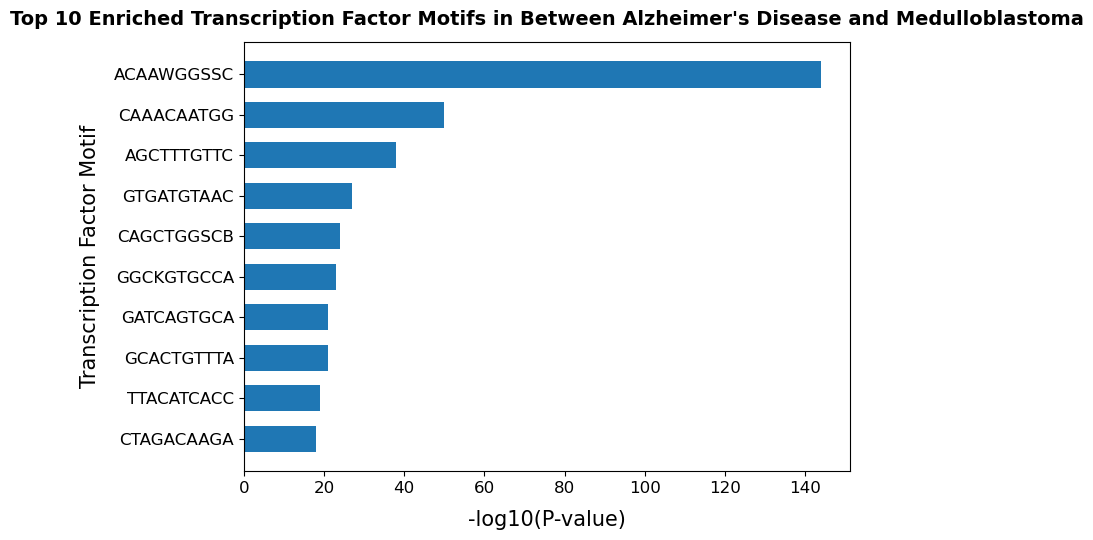

In [12]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5.5))

plt.barh(
    top10["Motif"][::-1],
    top10["-log10(P)"][::-1],
    height=0.65
)

# Increase label font sizes
plt.xlabel("-log10(P-value)", fontsize=15, labelpad=10)
plt.ylabel("Transcription Factor Motif", fontsize=15, labelpad=10)

plt.title(
    "Top 10 Enriched Transcription Factor Motifs in Between Alzheimer's Disease and Medulloblastoma",
    fontsize=14,
    fontweight="bold",
    pad=12
)

# Increase tick label sizes
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.tight_layout()

# Save high-resolution figures
plt.savefig(
    "/home/chromatin_results/Figure_5_4_Top10_Motifs.pdf",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    "/home/chromatin_results/Figure_5_4_Top10_Motifs.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [13]:
output = "/home/chromatin_results/Figure_5_4_Top10_Motifs.svg"

plt.savefig(
    output,
    format="svg",
    bbox_inches="tight"
)

print("Saved:", output)

Saved: /home/ankita/chromatin_results/Figure_5_4_Top10_Motifs.svg


<Figure size 640x480 with 0 Axes>

In [14]:
import pandas as pd
import numpy as np

gene_file = "/home/chromatin_results/differential_gene_list.txt"

with open(gene_file, "r") as f:
    genes = [line.strip() for line in f if line.strip()]

# Remove duplicates
genes = sorted(set(genes))

print("Unique genes:", len(genes))
print("First 20 genes:")
print(genes[:851])

Unique genes: 851
First 20 genes:
['A1BG-AS1', 'ABCA8', 'ABCG1', 'ABRACL', 'ACER2', 'ACSBG1', 'ACSS1', 'ACTE1P', 'ACTL6B', 'ACTL7B', 'ACTR3BP5', 'ACTRT2', 'ACYP2', 'ADAMTS14', 'ADAP1', 'ADCK1', 'ADCY5', 'ADCYAP1R1', 'ADD2', 'ADGRB1', 'ADORA3', 'ADPRS', 'AFAP1L1', 'AGPAT4', 'AHCY', 'AIF1L', 'AJAP1', 'AKAP6', 'ALCAM', 'ALDH3A1', 'AMN', 'AMPH', 'AMZ1', 'ANKRD2', 'ANXA13', 'ARHGAP1', 'ARHGAP23', 'ARHGAP39', 'ARID5B', 'ARK2C', 'ASB4', 'ASMER1', 'ATG13', 'ATP2C2', 'ATP5MC2', 'ATP8B3', 'ATPAF1', 'ATPSCKMT', 'AUTS2', 'B3GNT7', 'B4GALT6', 'BAGE2', 'BCL2', 'BCYRN1', 'BEGAIN', 'BIN1', 'BMP4', 'BPGM', 'BPI', 'BRMS1L', 'BRSK1', 'BRSK2', 'BTBD3', 'BUB3', 'C12orf76', 'C16orf95-DT', 'C1QBP', 'C1orf198', 'C7orf33', 'CACTIN', 'CADPS2', 'CALN1', 'CAPN12', 'CAPN2', 'CARNS1', 'CASKIN2', 'CCDC13-AS1', 'CCDC26', 'CCSER1', 'CD164', 'CD180', 'CD200', 'CD22', 'CD82', 'CD9', 'CDADC1', 'CDC42BPA', 'CDC42EP1', 'CDC42EP2', 'CDC42EP4', 'CDH1', 'CDH13-AS2', 'CDH15', 'CDK5R2', 'CDK5RAP2', 'CEMIP2', 'CEP97', 'CERCAM', 

In [15]:
from gprofiler import GProfiler

gp = GProfiler(return_dataframe=True)

results = gp.profile(
    organism="hsapiens",
    query=genes,
    sources=["GO:BP", "GO:MF", "GO:CC"],
    user_threshold=0.05,
    significance_threshold_method="fdr"
)

print("Total GO terms:", len(results))
print(results.columns.tolist())

Total GO terms: 296
['source', 'native', 'name', 'p_value', 'significant', 'description', 'term_size', 'query_size', 'intersection_size', 'effective_domain_size', 'precision', 'recall', 'query', 'parents']


In [16]:
significant_go = results[results["significant"] == True].copy()

significant_go = significant_go.sort_values("p_value")

print("Significant GO terms:", len(significant_go))

display(
    significant_go[
        [
            "source",
            "name",
            "p_value",
            "intersection_size",
            "term_size",
            "query_size"
        ]
    ].head(20)
)

Significant GO terms: 296


,source,name,p_value,intersection_size,term_size,query_size
0,GO:BP,nervous system development,2.224829e-20,166,2597,606
1,GO:BP,anatomical structure development,6.334333e-18,280,5948,606
2,GO:BP,developmental process,4.571529e-16,293,6535,606
3,GO:BP,neurogenesis,6.077567e-16,120,1769,606
4,GO:BP,system development,1.802741e-15,206,4023,606
5,GO:BP,multicellular organism development,9.571508e-15,227,4690,606
6,GO:CC,cell junction,2.602623e-14,140,2370,636
7,GO:BP,cellular developmental process,2.163248e-13,214,4444,606
8,GO:BP,cell differentiation,2.163248e-13,214,4443,606
9,GO:BP,generation of neurons,3.563332e-12,100,1523,606


In [17]:
output = "/home/ankita/chromatin_results/Significant_GO_Differential_Peaks.csv"

significant_go.to_csv(output, index=False)

print("Saved:", output)

Saved: /home/ankita/chromatin_results/Significant_GO_Differential_Peaks.csv


In [20]:
go_table = significant_go.head(15)[
    [
        "source",
        "name",
        "p_value",
        "intersection_size",
        "term_size",
        "query_size"
    ]
].copy()

output_table = "/home/chromatin_results/Figure_5_5_GO_Enrichment_Table.csv"

go_table.to_csv(output_table, index=False)

display(go_table)

print("\nTable saved to:")
print(output_table)

,source,name,p_value,intersection_size,term_size,query_size
0,GO:BP,nervous system development,2.224829e-20,166,2597,606
1,GO:BP,anatomical structure development,6.334333e-18,280,5948,606
2,GO:BP,developmental process,4.571529e-16,293,6535,606
3,GO:BP,neurogenesis,6.077567e-16,120,1769,606
4,GO:BP,system development,1.802741e-15,206,4023,606
5,GO:BP,multicellular organism development,9.571508e-15,227,4690,606
6,GO:CC,cell junction,2.602623e-14,140,2370,636
7,GO:BP,cellular developmental process,2.163248e-13,214,4444,606
8,GO:BP,cell differentiation,2.163248e-13,214,4443,606
9,GO:BP,generation of neurons,3.563332e-12,100,1523,606



Table saved to:
/home/ankita/chromatin_results/Figure_5_5_GO_Enrichment_Table.csv


In [21]:
print("GO category counts:")

print(
    significant_go["source"]
    .value_counts()
)

GO category counts:
source
GO:BP    204
GO:CC     73
GO:MF     19
Name: count, dtype: int64


In [22]:
display(
    significant_go[
        [
            "source",
            "name",
            "p_value",
            "intersection_size"
        ]
    ].head(15)
)

,source,name,p_value,intersection_size
0,GO:BP,nervous system development,2.224829e-20,166
1,GO:BP,anatomical structure development,6.334333e-18,280
2,GO:BP,developmental process,4.571529e-16,293
3,GO:BP,neurogenesis,6.077567e-16,120
4,GO:BP,system development,1.802741e-15,206
5,GO:BP,multicellular organism development,9.571508e-15,227
6,GO:CC,cell junction,2.602623e-14,140
7,GO:BP,cellular developmental process,2.163248e-13,214
8,GO:BP,cell differentiation,2.163248e-13,214
9,GO:BP,generation of neurons,3.563332e-12,100


In [23]:
display(
    significant_go[
        [
            "source",
            "name",
            "p_value",
            "intersection_size"
        ]
    ].head(15)
)

,source,name,p_value,intersection_size
0,GO:BP,nervous system development,2.224829e-20,166
1,GO:BP,anatomical structure development,6.334333e-18,280
2,GO:BP,developmental process,4.571529e-16,293
3,GO:BP,neurogenesis,6.077567e-16,120
4,GO:BP,system development,1.802741e-15,206
5,GO:BP,multicellular organism development,9.571508e-15,227
6,GO:CC,cell junction,2.602623e-14,140
7,GO:BP,cellular developmental process,2.163248e-13,214
8,GO:BP,cell differentiation,2.163248e-13,214
9,GO:BP,generation of neurons,3.563332e-12,100


In [24]:
top_go_genes = significant_go.head(10).copy()

for i, row in top_go_genes.iterrows():
    print("\nGO term:", row["name"])
    print("Category:", row["source"])
    print("P-value:", row["p_value"])
    print("Number of genes:", row["intersection_size"])
    print("Genes:", row["query"])


GO term: nervous system development
Category: GO:BP
P-value: 2.2248291682617746e-20
Number of genes: 166
Genes: query_1

GO term: anatomical structure development
Category: GO:BP
P-value: 6.334333484956898e-18
Number of genes: 280
Genes: query_1

GO term: developmental process
Category: GO:BP
P-value: 4.571529476549438e-16
Number of genes: 293
Genes: query_1

GO term: neurogenesis
Category: GO:BP
P-value: 6.077567463431588e-16
Number of genes: 120
Genes: query_1

GO term: system development
Category: GO:BP
P-value: 1.8027411541788143e-15
Number of genes: 206
Genes: query_1

GO term: multicellular organism development
Category: GO:BP
P-value: 9.571507517694573e-15
Number of genes: 227
Genes: query_1

GO term: cell junction
Category: GO:CC
P-value: 2.602623227381887e-14
Number of genes: 140
Genes: query_1

GO term: cellular developmental process
Category: GO:BP
P-value: 2.1632480771196035e-13
Number of genes: 214
Genes: query_1

GO term: cell differentiation
Category: GO:BP
P-value: 2.1

In [26]:
import os

files = [
    "/home/chromatin_results/Significant_GO_Differential_Peaks.csv",
    "/home/chromatin_results/Figure_5_5_GO_Enrichment.svg",
    "/home/chromatin_results/Figure_5_5_GO_DotPlot.svg",
    "/home/chromatin_results/Figure_5_5_GO_Enrichment_Table.csv"
]

for f in files:
    print(
        "✓" if os.path.exists(f) else "✗",
        os.path.basename(f)
    )

✓ Significant_GO_Differential_Peaks.csv
✓ Figure_5_5_GO_Enrichment.svg
✓ Figure_5_5_GO_DotPlot.svg
✓ Figure_5_5_GO_Enrichment_Table.csv


In [35]:
from gprofiler import GProfiler

gp = GProfiler(return_dataframe=True)

kegg_results = gp.profile(
    organism="hsapiens",
    query=genes,
    sources=["KEGG"],
    user_threshold=1.0,
    significance_threshold_method="fdr"
)

print("Total KEGG pathways:", len(kegg_results))

Total KEGG pathways: 291


In [38]:
kegg_plot = kegg_results.sort_values("p_value").head(20).copy()

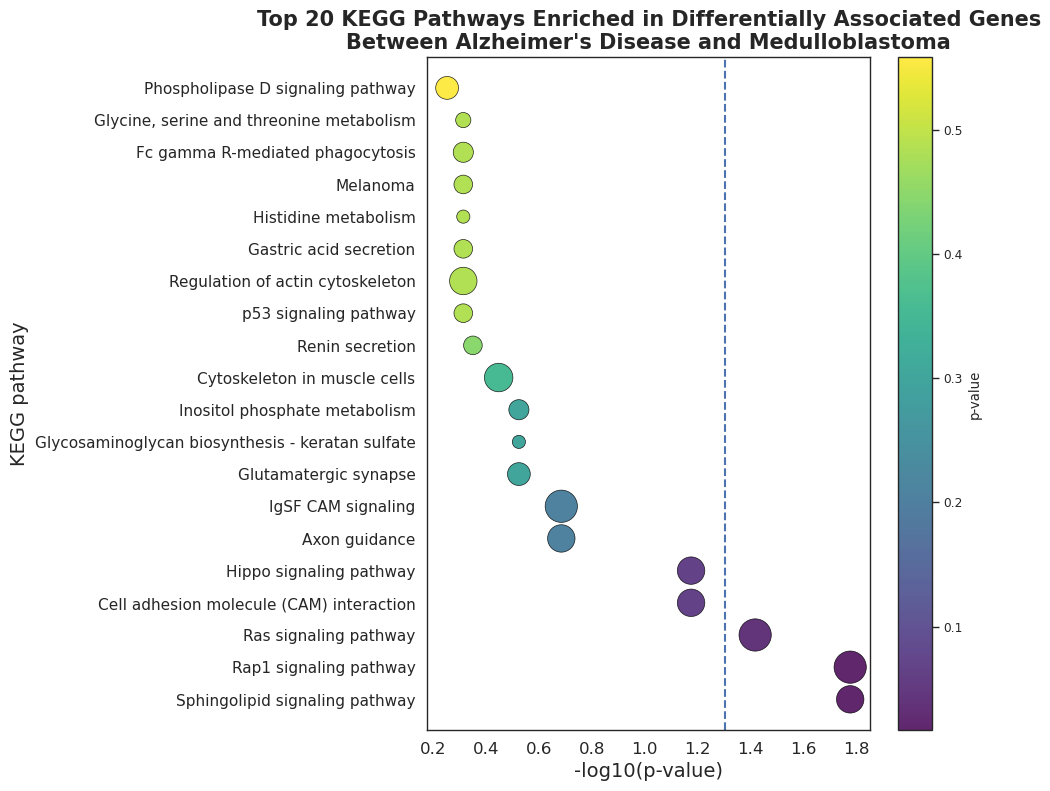

In [39]:
import numpy as np
import matplotlib.pyplot as plt

kegg_plot = kegg_results.sort_values("p_value").head(20).copy()

kegg_plot["-log10(p-value)"] = -np.log10(kegg_plot["p_value"])

plt.figure(figsize=(10, 8))

scatter = plt.scatter(
    kegg_plot["-log10(p-value)"],
    range(len(kegg_plot)),
    s=kegg_plot["intersection_size"] * 30,
    c=kegg_plot["p_value"],
    cmap="viridis",
    alpha=0.85,
    edgecolors="black",
    linewidths=0.5
)

plt.yticks(
    range(len(kegg_plot)),
    kegg_plot["name"],
    fontsize=11
)

plt.xlabel("-log10(p-value)", fontsize=14)
plt.ylabel("KEGG pathway", fontsize=14)

plt.title(
    "Top 20 KEGG Pathways Enriched in Differentially Associated Genes\n"
    "Between Alzheimer's Disease and Medulloblastoma",
    fontsize=15,
    fontweight="bold"
)

plt.axvline(
    -np.log10(0.05),
    linestyle="--",
    linewidth=1.5
)

plt.colorbar(
    scatter,
    label="p-value"
)

plt.xticks(fontsize=12)

plt.tight_layout()

plt.savefig(
    "Figure_5_5_KEGG_Top20.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

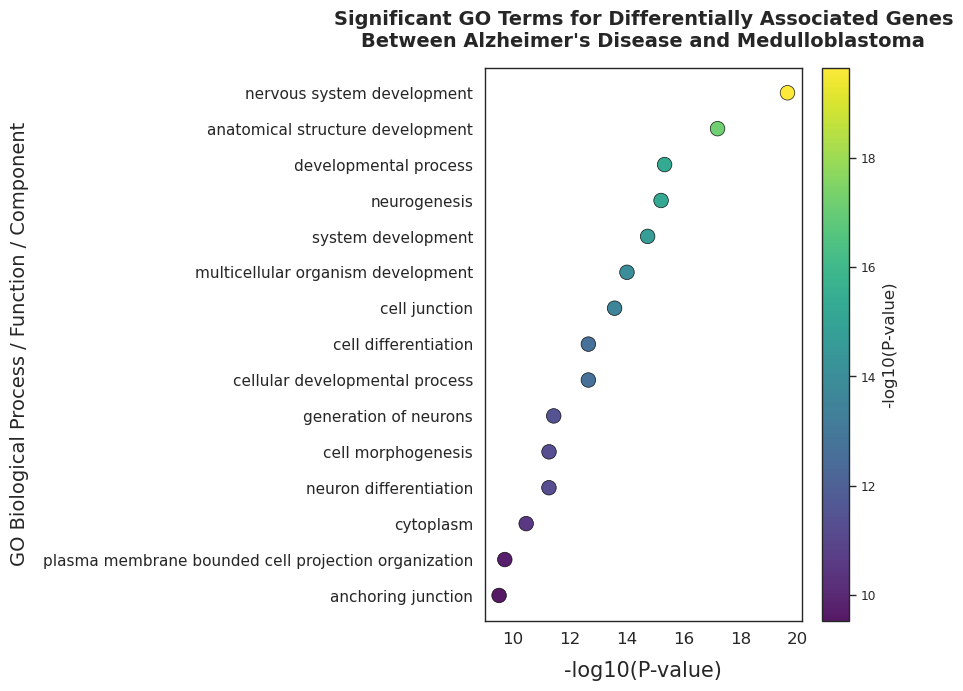

Figures saved successfully:
/home/ankita/chromatin_results/Figure_5_5_GO_Enrichment_ColourDotPlot.svg


In [42]:
import matplotlib.pyplot as plt
import numpy as np

# Take top 15 significant GO terms
top_go = significant_go.head(15).copy()

# Calculate -log10(P-value)
top_go["minus_log10_p"] = -np.log10(
    top_go["p_value"].replace(0, np.nextafter(0, 1))
)

# Reverse order so the most significant term appears at the top
top_go = top_go.sort_values(
    "minus_log10_p",
    ascending=True
)

# Create a smaller figure
plt.figure(figsize=(9, 7))

# Colour values based on significance
colors = top_go["minus_log10_p"]

# Colourful dot plot
scatter = plt.scatter(
    top_go["minus_log10_p"],
    top_go["name"],
    s=110,
    c=colors,
    cmap="viridis",
    alpha=0.9,
    edgecolors="black",
    linewidths=0.5
)

# Colourbar
cbar = plt.colorbar(scatter)
cbar.set_label(
    "-log10(P-value)",
    fontsize=12
)

# Increase font sizes
plt.xlabel(
    "-log10(P-value)",
    fontsize=15,
    labelpad=10
)

plt.ylabel(
    "GO Biological Process / Function / Component",
    fontsize=14,
    labelpad=10
)

plt.title(
    "Significant GO Terms for Differentially Associated Genes\n"
    "Between Alzheimer's Disease and Medulloblastoma",
    fontsize=14,
    fontweight="bold",
    pad=15
)

# Increase tick label sizes
plt.xticks(fontsize=12)
plt.yticks(fontsize=11)

plt.tight_layout()

# Save SVG
output_fig = (
    "/home/ankita/chromatin_results/"
    "Figure_5_5_GO_Enrichment_ColourDotPlot.svg"
)

plt.savefig(
    output_fig,
    format="svg",
    bbox_inches="tight"
)

# Save high-resolution PNG
plt.savefig(
    "/home/chromatin_results/"
    "Figure_5_5_GO_Enrichment_ColourDotPlot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figures saved successfully:")
print(output_fig)